In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score
from imblearn.over_sampling import RandomOverSampler

In [3]:
# Load data
import pandas as pd
df = pd.read_csv(r"C:\Users\Admin\Desktop\CS\ML Class\csv files\STRIKE_REPORTS.csv", low_memory=False)
df.head()

,INDEX_NR,INCIDENT_DATE,INCIDENT_MONTH,INCIDENT_YEAR,TIME,TIME_OF_DAY,AIRPORT_ID,AIRPORT,LATITUDE,LONGITUDE,...,SIZE,NR_INJURIES,NR_FATALITIES,COMMENTS,REPORTED_NAME,REPORTED_TITLE,SOURCE,PERSON,LUPDATE,TRANSFER
0,608242,6/22/1996,6,1996,NaN,NaN,KSMF,SACRAMENTO INTL,38.69542,-121.59077,...,Medium,NaN,NaN,/Legacy Record=100001/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,12/20/2007,False
1,608243,6/26/1996,6,1996,NaN,NaN,KDEN,DENVER INTL AIRPORT,39.85841,-104.66700,...,Medium,NaN,NaN,/Legacy Record=100002/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,12/20/2007,False
2,608244,7/1/1996,7,1996,NaN,NaN,KOMA,EPPLEY AIRFIELD,41.30252,-95.89417,...,Medium,NaN,NaN,/Legacy Record=100003/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,12/20/2007,False
3,608245,7/1/1996,7,1996,NaN,NaN,KIAD,WASHINGTON DULLES INTL ARPT,38.94453,-77.45581,...,Medium,NaN,NaN,/Legacy Record=100004/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,12/20/2007,False
4,608246,7/1/1996,7,1996,NaN,NaN,KLGA,LA GUARDIA ARPT,40.77724,-73.87261,...,Medium,NaN,NaN,/Legacy Record=100005/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,12/20/2007,False


In [4]:
#Lowercase Columns
df.columns = [cols.lower() for cols in df.columns]
df.head()

,index_nr,incident_date,incident_month,incident_year,time,time_of_day,airport_id,airport,latitude,longitude,...,size,nr_injuries,nr_fatalities,comments,reported_name,reported_title,source,person,lupdate,transfer
0,608242,6/22/1996,6,1996,NaN,NaN,KSMF,SACRAMENTO INTL,38.69542,-121.59077,...,Medium,NaN,NaN,/Legacy Record=100001/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,12/20/2007,False
1,608243,6/26/1996,6,1996,NaN,NaN,KDEN,DENVER INTL AIRPORT,39.85841,-104.66700,...,Medium,NaN,NaN,/Legacy Record=100002/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,12/20/2007,False
2,608244,7/1/1996,7,1996,NaN,NaN,KOMA,EPPLEY AIRFIELD,41.30252,-95.89417,...,Medium,NaN,NaN,/Legacy Record=100003/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,12/20/2007,False
3,608245,7/1/1996,7,1996,NaN,NaN,KIAD,WASHINGTON DULLES INTL ARPT,38.94453,-77.45581,...,Medium,NaN,NaN,/Legacy Record=100004/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,12/20/2007,False
4,608246,7/1/1996,7,1996,NaN,NaN,KLGA,LA GUARDIA ARPT,40.77724,-73.87261,...,Medium,NaN,NaN,/Legacy Record=100005/,REDACTED,REDACTED,Air Transport Report,Air Transport Operations,12/20/2007,False


In [5]:
#Data Information 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 288810 entries, 0 to 288809
Data columns (total 100 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   index_nr               288810 non-null  int64  
 1   incident_date          288810 non-null  str    
 2   incident_month         288810 non-null  int64  
 3   incident_year          288810 non-null  int64  
 4   time                   163633 non-null  str    
 5   time_of_day            166394 non-null  str    
 6   airport_id             288804 non-null  str    
 7   airport                288810 non-null  str    
 8   latitude               253309 non-null  float64
 9   longitude              253308 non-null  float64
 10  runway                 218852 non-null  str    
 11  state                  253309 non-null  str    
 12  faaregion              253309 non-null  str    
 13  location               33939 non-null   str    
 14  enroute_state          5037 non-null    str   

In [6]:
# Only keeping numerical features + target (Removed all text categories)
cols = ['latitude', 'longitude', 'height', 'speed', 'num_engs', 'indicated_damage']
df = df[cols].dropna()
df.head()

,latitude,longitude,height,speed,num_engs,indicated_damage
5,29.53369,-98.46978,0.0,100.0,3.0,False
6,39.29761,-94.71391,1500.0,220.0,2.0,True
8,32.89595,-97.03720,100.0,135.0,2.0,False
10,38.74769,-90.35999,200.0,70.0,1.0,True
11,33.36996,-81.96450,0.0,100.0,2.0,False


In [7]:
# Describe
df.describe()

,latitude,longitude,height,speed,num_engs
count,88243.000000,88243.000000,88243.000000,88243.000000,88243.000000
mean,41.711953,-88.228263,1057.212651,143.309962,2.021169
std,1652.454731,553.533667,1956.301166,46.627773,0.425689
min,-34.838417,-177.381000,0.000000,0.000000,1.000000
25%,32.895950,-97.501220,0.000000,120.000000,2.000000
50%,37.721290,-87.752420,150.000000,140.000000,2.000000
75%,40.692500,-80.232870,1200.000000,160.000000,2.000000
max,490905.000000,164140.000000,29000.000000,1250.000000,4.000000


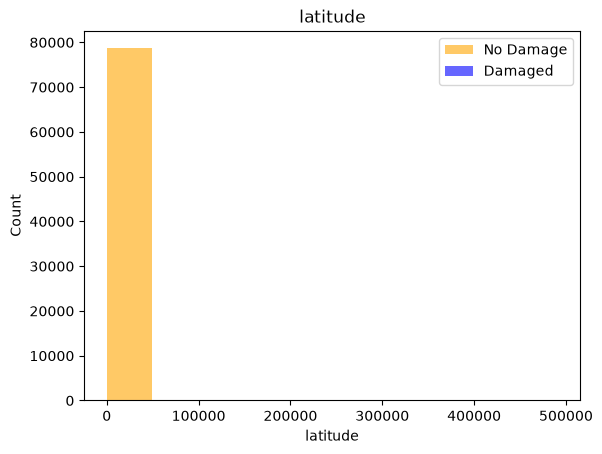

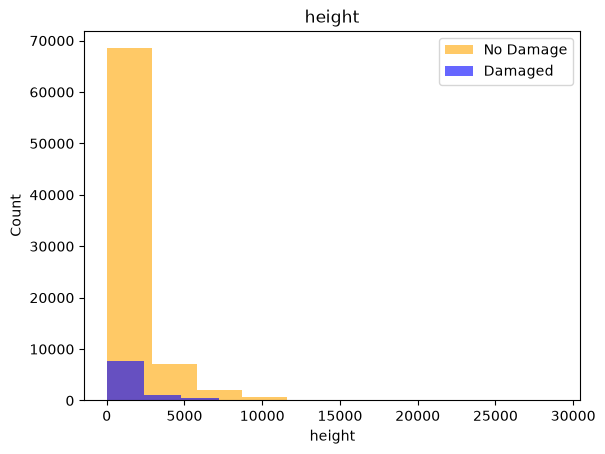

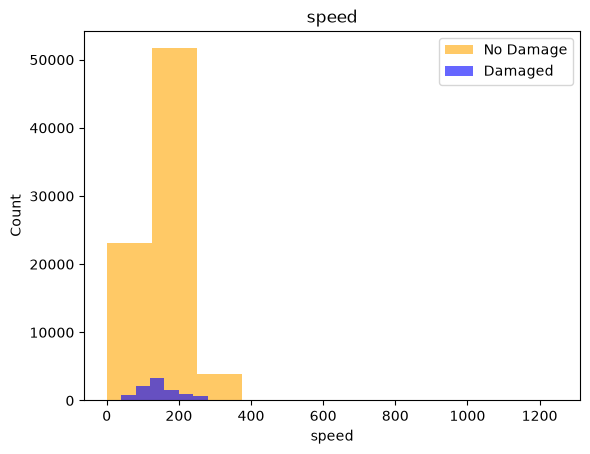

In [8]:
#Histograms
import matplotlib.pyplot as plt
for label in ['latitude','height','speed']:
    plt.hist(df[df['indicated_damage']==False][label], color="orange", label='No Damage', alpha=0.6)
    plt.hist(df[df['indicated_damage']==True][label], color="blue", label='Damaged', alpha=0.6)
    plt.title(label)
    plt.ylabel("Count")
    plt.xlabel(label)
    plt.legend()
    plt.show()

In [9]:
#Split X/Y
X = df.drop(columns=['indicated_damage'])
y = df['indicated_damage'].astype(int)  # False -> 0, True -> 1, NO lambda
print(y.value_counts())

indicated_damage
0    78633
1     9610
Name: count, dtype: int64


In [10]:
#Train- Test- Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(len(X_train))
print(len(X_test))
print(y_train.value_counts())

70594
17649
indicated_damage
0    62906
1     7688
Name: count, dtype: int64


In [11]:
#Preprocessing
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Scaled X_train shape:", X_train.shape)

Scaled X_train shape: (70594, 5)


In [12]:
# KNN look at the natural data distribution
X_train_bal = X_train
y_train_bal = y_train
print("Training rows:", len(X_train_bal))

Training rows: 70594


In [15]:
#KNN Model Training
from sklearn.neighbors import KNeighborsClassifier
Knn_model = KNeighborsClassifier(n_neighbors=1)
Knn_model.fit(X_train_bal, y_train_bal)
Knn_model

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [16]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predicting on training data calculates your memorization accuracy
y_pred_train = Knn_model.predict(X_train)

print("--- KNN Training Metrics ---")
print("Accuracy:", accuracy_score(y_train, y_pred_train))
print("\nClassification Report:\n", classification_report(y_train, y_pred_train))
print("Confusion Matrix:\n", confusion_matrix(y_train, y_pred_train))

--- KNN Training Metrics ---
Accuracy: 0.9509306739949571

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.97      0.97     62906
           1       0.77      0.78      0.77      7688

    accuracy                           0.95     70594
   macro avg       0.87      0.87      0.87     70594
weighted avg       0.95      0.95      0.95     70594

Confusion Matrix:
 [[61171  1735]
 [ 1729  5959]]
